# A-1 Chlorophyll Pocket Comparison — CORRECTED (v2)

**Research question:** Why might A-1B bind **chlorophyll f** (`F6C`) while A-1A contains **chlorophyll a** (`CLA`)?

**Structures:** far-red PSI `9I9L`, independent structure `9EYS`, optional white-light PSI `1JB0`.

> **Corrections in v2:** (1) Use authoritative PDB ligand identities (`F6C` = Chl f; `CLA` = Chl a). (2) Locate the C2 formyl group with **CMB–OMB** on F6C, not a carbonyl elsewhere in the molecule. (3) Require correct A-1A/ A-1B pairing and validate geometry. (4) Distinguish real OMB measurements from hypothetical planar formyl-O probes on CLA. (5) Save files with the suffix `_corrected_v2` to avoid overwriting the first run.

**Important scientific caveat:** Automatic A-1 assignments and hypothetical probe orientations must be checked against the structural paper. Close N/O atoms are *potential hydrogen-bond contacts*, not demonstrated hydrogen bonds. These measurements establish correlations, not causation.

**Save location:** `My Drive/Rabia..Australia/{Structures, Figures, Reports, Tables, Logs, Scripts}`.

**Usage:** Run all cells top to bottom in Google Colab. No GPU required.

**This version includes a safe automatic cleanup section:** after both corrected analyses finish, it **moves** the old reports, figures, tables, and logs out of the working folders into `Old_Version_Backup/` (it does *not* permanently delete them). The original notebook is moved only after you save this corrected notebook into `Scripts/`.


## Step 1 — Install Python libraries
Run this once per new Colab session. No GPU is required.

In [1]:
%pip -q install biopython numpy matplotlib pandas


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 54.4 MB/s eta 0:00:00


## Step 2 — Connect Google Drive
Sign in and grant access. The notebook saves outputs in your own Drive.

In [2]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## Step 3 — Configure the corrected analysis and output folders
Outputs get `_corrected_v2` filenames, preserving the first run. Note the **two dots** in `Rabia..Australia`.

In [3]:
from pathlib import Path
from contextlib import redirect_stdout
from datetime import datetime, timezone
from types import SimpleNamespace
from urllib.error import HTTPError, URLError
from urllib.request import urlopen
import csv
import re
import shutil
import sys
import traceback
import warnings

import numpy as np
import pandas as pd
from Bio.Align import PairwiseAligner, substitution_matrices
from Bio.PDB import NeighborSearch
from Bio.PDB.MMCIFParser import MMCIFParser
import matplotlib.pyplot as plt
from IPython.display import display, Image

PROJECT_ROOT = Path('/content/drive/MyDrive/Rabia..Australia')
DEFAULT_OUTPUT_ROOT = PROJECT_ROOT
MAX_A0_DISTANCE = 14.0
MIN_CHAIN_LENGTH = 600

# A-1 sites are selected from Met-ligated A0 neighbors, then by pigment identity.
# VERIFY the printed candidate table for all three copies before interpreting.
# If needed, replace (None, None) with ('chain:resnum', 'chain:resnum').
SITE_OVERRIDES = {
    '9i9l': (None, None),
    '9eys': (None, None),
}

warnings.filterwarnings('ignore', message='Mean of empty slice')


In [4]:
def make_folders(root):
    root = Path(root).expanduser()
    # Avoid accidentally saving to temporary Colab storage instead of Drive.
    if root == DEFAULT_OUTPUT_ROOT and not Path("/content/drive/MyDrive").is_dir():
        raise RuntimeError(
            "Google Drive is not mounted. In a Colab notebook run:\n"
            "    from google.colab import drive\n"
            "    drive.mount('/content/drive')\n"
            "Then run this script again."
        )
    folders = {name: root / name for name in
               ("Structures", "Figures", "Reports", "Tables", "Logs", "Scripts")}
    for folder in folders.values():
        folder.mkdir(parents=True, exist_ok=True)
    return folders


In [5]:
FOLDERS = make_folders(PROJECT_ROOT)
print('Project folder:', PROJECT_ROOT)
for name, folder in FOLDERS.items():
    print(f'  {name:11s} → {folder}')


Project folder: /content/drive/MyDrive/Rabia..Australia
  Structures  → /content/drive/MyDrive/Rabia..Australia/Structures
  Figures     → /content/drive/MyDrive/Rabia..Australia/Figures
  Reports     → /content/drive/MyDrive/Rabia..Australia/Reports
  Tables      → /content/drive/MyDrive/Rabia..Australia/Tables
  Logs        → /content/drive/MyDrive/Rabia..Australia/Logs
  Scripts     → /content/drive/MyDrive/Rabia..Australia/Scripts


## Step 4 — Download and save the protein structures
The 9I9L and 9EYS files are downloaded only when missing, and are kept inside `Structures/`. 1JB0 is downloaded later **only** if you enable the optional comparison.

In [6]:
def ensure_structure(filename, folder):
    """Keep a copy of every mmCIF input inside Drive's Structures folder.

    A basename such as 9i9l.cif searches Structures first.  If it does not
    exist, a known-format PDB ID is fetched from RCSB into that directory.
    Existing local or absolute CIF paths are also copied there.
    """
    requested = Path(filename).expanduser()
    destination = folder / requested.name
    if requested.is_file():
        if requested.resolve() != destination.resolve():
            shutil.copy2(requested, destination)
        return destination
    if destination.is_file():
        return destination

    match = re.fullmatch(r"([A-Za-z0-9]{4})\.cif", requested.name, flags=re.IGNORECASE)
    if match:
        pdb_id = match.group(1).upper()
        url = f"https://files.rcsb.org/download/{pdb_id}.cif"
        temporary = destination.with_name(destination.name + ".download")
        print(f"Downloading {pdb_id} from RCSB into {destination} ...")
        try:
            with urlopen(url, timeout=90) as source, temporary.open("wb") as target:
                shutil.copyfileobj(source, target)
            if temporary.stat().st_size == 0:
                raise RuntimeError(f"Downloaded CIF for {pdb_id} was empty")
            temporary.replace(destination)
        except (HTTPError, URLError, OSError, RuntimeError) as exc:
            temporary.unlink(missing_ok=True)
            raise RuntimeError(
                f"Could not download {pdb_id}. Put {requested.name} in "
                f"{folder} and retry. Original error: {exc}"
            ) from exc
        return destination
    raise FileNotFoundError(
        f"Structure file '{filename}' not found. Upload it into {folder}, "
        "or use --cif with an existing file path."
    )


In [7]:
STRUCTURES = {
    pdb: ensure_structure(f'{pdb}.cif', FOLDERS['Structures'])
    for pdb in ('9i9l', '9eys')
}
for pdb, location in STRUCTURES.items():
    print(f'{pdb.upper()}: {location} ({location.stat().st_size / 1024**2:.1f} MB)')


9I9L: /content/drive/MyDrive/Rabia..Australia/Structures/9i9l.cif (8.9 MB)
9EYS: /content/drive/MyDrive/Rabia..Australia/Structures/9eys.cif (9.0 MB)


## Step 5 — Scientific constants and correct PDB ligand assignments
`F6C` = **chlorophyll f** (`CMB` formyl carbon, `OMB` formyl oxygen); `CLA` = **chlorophyll a** (`CMB` methyl carbon, no `OMB`). The atom bonded to `CMB` on both pigments is `C2B`. We verify that geometry rather than searching for an arbitrary carbonyl.

In [8]:
RING_N = ("NA", "NB", "NC", "ND")

TAIL = re.compile(r"^C\d{1,2}$")

AA3 = {"ALA": "A", "ARG": "R", "ASN": "N", "ASP": "D", "CYS": "C", "GLN": "Q", "GLU": "E",
       "GLY": "G", "HIS": "H", "ILE": "I", "LEU": "L", "LYS": "K", "MET": "M", "PHE": "F",
       "PRO": "P", "SER": "S", "THR": "T", "TRP": "W", "TYR": "Y", "VAL": "V"}

CHARGE = {"ASP": -1, "GLU": -1, "LYS": 1, "ARG": 1}

CHG_ATOMS = {"ASP": ("OD1", "OD2"), "GLU": ("OE1", "OE2"), "LYS": ("NZ",), "ARG": ("NE", "NH1", "NH2")}

RING_ATOMS = {"PHE": ("CG", "CD1", "CD2", "CE1", "CE2", "CZ"),
              "TYR": ("CG", "CD1", "CD2", "CE1", "CE2", "CZ"),
              "TRP": ("CD2", "CE2", "CE3", "CZ2", "CZ3", "CH2")}

O_ANGLE = np.deg2rad(57.0)  # idealized outboard-to-oxygen angle; virtual, not experimentally measured
PIGMENT_NAMES = {'F6C': 'Chl f', 'CLA': 'Chl a'}
CORRECTION_SUFFIX = '_corrected_v2'
FORMYL_O_BOND_MIN, FORMYL_O_BOND_MAX = 1.05, 1.42
C2_RING_BOND_MIN, C2_RING_BOND_MAX = 1.25, 1.70


In [9]:
def xyz(a):
    return np.asarray(a.coord, dtype=float)


def dist(p, q):
    return float(np.linalg.norm(np.asarray(p, float) - np.asarray(q, float)))


def lab(a):
    r = a.get_parent()
    return f"{r.get_parent().id}:{r.get_resname()}{r.id[1]}:{a.get_id()}"


def rlab(r):
    return f"{r.get_parent().id}:{r.get_resname()}{r.id[1]}"


def is_chl(r):
    # Only the two explicitly identified chlorophyll types used in this analysis.
    return r.get_resname() in PIGMENT_NAMES and "MG" in r and sum(a.element == "N" for a in r) >= 4


def pigment_type(res):
    name = res.get_resname()
    if name not in PIGMENT_NAMES:
        raise ValueError(f"Unexpected pigment {rlab(res)}; inspect ligands in the mmCIF")
    return PIGMENT_NAMES[name]


def c2_substituent(res):
    """Return (CMB, OMB_or_None) using known ligand naming; fail on invalid bonds."""
    name = res.get_resname()
    if name not in PIGMENT_NAMES:
        raise ValueError(f"Cannot classify {rlab(res)} as chlorophyll a/f")
    if not ("CMB" in res and "C2B" in res):
        raise ValueError(f"{rlab(res)} missing CMB or C2B")
    c, attach = res["CMB"], res["C2B"]
    d = dist(xyz(c), xyz(attach))
    if not (C2_RING_BOND_MIN <= d <= C2_RING_BOND_MAX):
        raise ValueError(f"{rlab(res)} has invalid C2B–CMB distance: {d:.2f} Å")
    if name == "F6C":
        if "OMB" not in res:
            raise ValueError(f"{rlab(res)} F6C missing formyl oxygen OMB")
        o = res["OMB"]
        dco = dist(xyz(c), xyz(o))
        if not (FORMYL_O_BOND_MIN <= dco <= FORMYL_O_BOND_MAX):
            raise ValueError(f"{rlab(res)} has invalid CMB–OMB distance: {dco:.2f} Å")
        return c, o
    if "OMB" in res:
        raise ValueError(f"Unexpected OMB in {rlab(res)} (CLA)")
    return c, None


def axial_ligand(ns, res, rad=3.5):
    mg, own, best = xyz(res["MG"]), set(res.get_atoms()), None
    for a in ns.search(mg, rad, "A"):
        if a in own or a.element not in ("N", "O", "S"):
            continue
        d = dist(xyz(a), mg)
        if best is None or d < best[1]:
            best = (a, d)
    return best


def ring_normal(res):
    pts = np.array([xyz(res[n]) for n in RING_N if n in res])
    if len(pts) < 4:
        raise ValueError(f"Missing ring nitrogens in {rlab(res)}")
    return np.linalg.svd(pts - pts.mean(axis=0))[2][-1]


def planar_probes(c, attach, normal):
    """Two *idealized* in-plane formyl-O probes (not torsion-optimized geometries)."""
    u = xyz(c) - xyz(attach)
    u /= np.linalg.norm(u)
    w = np.cross(normal, u)
    w /= np.linalg.norm(w)
    return [xyz(c) + 1.22 * (np.cos(O_ANGLE) * u + sign * np.sin(O_ANGLE) * w)
            for sign in (1, -1)]


def clearance(ns, point, own, radius=4.0):
    best = (radius, None)
    for atom in ns.search(np.asarray(point, float), radius, "A"):
        if atom in own:
            continue
        d = dist(xyz(atom), point)
        if d < best[0]:
            best = (d, atom)
    return best


def contact_type(atom, d):
    if atom is None:
        return "none within search radius"
    if d < 2.5 or (atom.element in ("C", "S") and d < 3.0):
        return "potential steric clash"
    if atom.element in ("N", "O") and 2.5 <= d <= 3.3:
        return "potential polar contact"
    return "nonbonded contact"


def polar_partners(ns, point, own, radius=3.3):
    """Nearby N/O positions only; hydrogen-bond geometry is NOT confirmed."""
    return sorted((dist(xyz(a), point), lab(a))
                  for a in ns.search(np.asarray(point, float), radius, "A")
                  if a not in own and a.element in ("N", "O"))

## Step 6 — Measure the pocket around C2B–CMB for each site
For **Chl a (CLA)**, position *two hypothetical planar* oxygens next to CMB and measure steric clearance. For **Chl f (F6C)**, use the *actual deposited* `OMB` atom. Other properties (packing, Phe/Cys proximity and charge) use the same CMB-based center.

In [10]:
def site_metrics(ns, res):
    c, o = c2_substituent(res)  # fail loudly if ligand geometry is invalid
    own = set(res.get_atoms())
    axial = axial_ligand(ns, res)
    cc = xyz(c)
    pocket = {}
    for pt in [cc] + ([xyz(o)] if o is not None else []):
        for a in ns.search(pt, 4.5, "A"):
            r = a.get_parent()
            if a not in own and r.id[0] == " ":
                pocket[r] = (r.get_parent().id, r.id[1], r.get_resname())

    m = {
        "res": res, "where": f"{res.get_parent().id}:{res.id[1]}",
        "name": res.get_resname(), "pigment": pigment_type(res),
        "formyl": bool(o is not None), "c2name": "CMB", "attach": "C2B",
        "axial": f"{lab(axial[0])} ({axial[1]:.2f} Å)" if axial else "none within 3.5 Å",
        "c2_ring_bond_A": dist(cc, xyz(res['C2B'])),
        "pocket": pocket,
        "packing": sum(1 for a in ns.search(cc, 5.0, "A") if a not in own),
        "best_probe": float('nan'), "real_o": None,
        "hbond_partners": None, "probes": [], "probe_match_offset": float('nan'),
    }
    normal = ring_normal(res)
    if o is None:  # CLA = Chl a, methyl: hypothetical formyl oxygen
        for p in planar_probes(c, res['C2B'], normal):
            d, atom = clearance(ns, p, own)
            m['probes'].append({"d": d, "kind": contact_type(atom, d),
                                "who": lab(atom) if atom is not None else "none within 4 Å",
                                "p": p, "partners": polar_partners(ns, p, own)})
        m['best_probe'] = max(q['d'] for q in m['probes'])
    else:  # F6C = Chl f, real formyl oxygen
        d, atom = clearance(ns, xyz(o), own)
        m['real_o'] = {"d": d, "kind": contact_type(atom, d),
                       "who": lab(atom) if atom is not None else "none within 4 Å"}
        m['hbond_partners'] = polar_partners(ns, xyz(o), own)
        m['c2_o_bond_A'] = dist(cc, xyz(o))
        # Diagnostic only: actual OMB may be twisted out of the model's planar probe geometry.
        m['probe_match_offset'] = min(dist(p, xyz(o))
                                      for p in planar_probes(c, res['C2B'], normal))

    near = {a.get_parent() for a in ns.search(cc, 9.0, "A")}
    aromatic = None
    for r in near:
        if r.id[0] == " " and r.get_resname() in RING_ATOMS:
            pts = [xyz(r[name]) for name in RING_ATOMS[r.get_resname()] if name in r]
            if len(pts) >= 5:
                d = dist(np.mean(pts, axis=0), cc)
                if aromatic is None or d < aromatic[0]:
                    aromatic = (d, rlab(r))
    m['aromatic'] = aromatic
    cys = [(dist(xyz(r['SG']), cc), rlab(r)) for r in near
           if r.id[0] == ' ' and r.get_resname() == 'CYS' and 'SG' in r]
    m['cys'] = min(cys) if cys else None
    charge = {}
    for a in ns.search(cc, 8.0, 'A'):
        r = a.get_parent()
        if r.id[0] == ' ' and a.get_id() in CHG_ATOMS.get(r.get_resname(), ()):
            charge[r] = CHARGE[r.get_resname()]
    m['charge8'] = sum(charge.values())
    m['charged_list'] = sorted(rlab(r) for r in charge)
    return m

## Step 7 — Find and validate the A-1 chlorophyll pairs
A0 = Met-ligated Mg center. For each A0, find the nearest non-Met chlorophyll within 14 Å. Choose A-1A from **CLA**, A-1B from **F6C**, then pair them by proximity. **Read the candidate table:** ligand identity alone does not prove the biological A-1 label.

In [11]:
def find_pairs(model, ns, max_a0_dist):
    chls = [r for ch in model for r in ch if is_chl(r)]
    info = {}
    for r in chls:
        ax = axial_ligand(ns, r)
        info[r] = dict(mg=xyz(r['MG']), f=(r.get_resname() == 'F6C'),
                       lig=f"{ax[0].get_parent().get_resname()}{ax[0].get_parent().id[1]}:{ax[0].get_id()}" if ax else "none")
    a0s = [r for r in chls if info[r]['lig'].startswith('MET')]
    candidates = {}
    for a0 in a0s:
        other = [x for x in chls if x is not a0 and not info[x]['lig'].startswith('MET')]
        if not other:
            continue
        near = min(other, key=lambda x: dist(info[x]['mg'], info[a0]['mg']))
        d = dist(info[near]['mg'], info[a0]['mg'])
        if d <= max_a0_dist:
            candidates[near] = (a0, d)
    print(f"{len(chls)} Chl a/f pigments, {len(a0s)} Met-ligated A0 candidates, "
          f"{len(candidates)} A-1 candidates")
    print(f"{'A-1 candidate':<16} {'pigment':<9} {'formyl':<7} {'axial':<15} {'nearest A0':<12} {'Mg–Mg Å':>8}")
    for x, (a0, d) in sorted(candidates.items(), key=lambda kv: (kv[0].get_parent().id, kv[0].id[1])):
        print(f"{x.get_parent().id + ':' + str(x.id[1]):<16} {x.resname:<9} "
              f"{str(info[x]['f']):<7} {info[x]['lig']:<15} "
              f"{a0.get_parent().id + ':' + str(a0.id[1]):<12} {d:8.2f}")
    fs = [x for x in candidates if x.resname == 'F6C']
    nonf = [x for x in candidates if x.resname == 'CLA']
    if not fs or len(fs) != len(nonf):
        raise RuntimeError(f"Expected paired F6C and CLA candidates, got {len(fs)} F6C and {len(nonf)} CLA")
    pairs, used = [], set()
    for b in sorted(fs, key=lambda x: (x.get_parent().id, x.id[1])):
        available = [x for x in nonf if x not in used]
        a = min(available, key=lambda x: dist(info[x]['mg'], info[b]['mg']))
        dd = dist(info[a]['mg'], info[b]['mg'])
        if dd > 35.0:
            raise RuntimeError(f"Candidate pair {rlab(a)} / {rlab(b)} separated by {dd:.1f} Å")
        used.add(a)
        pairs.append((a, b))
        print(f"Pair {len(pairs)}: A-1A {rlab(a)} ({a.resname}) / "
              f"A-1B {rlab(b)} ({b.resname}); Mg–Mg {dd:.2f} Å")
    return pairs, candidates, info


def get_chl(model, spec):
    cid, number = spec.split(':')
    for r in model[cid]:
        if r.id[1] == int(number) and is_chl(r):
            return r
    raise ValueError(f"No CLA/F6C chlorophyll at {spec}")


def validate_pair(a, b):
    if a.resname != 'CLA' or b.resname != 'F6C':
        raise ValueError(f"Wrong pigment order: A-1A {rlab(a)} is {a.resname}; "
                         f"A-1B {rlab(b)} is {b.resname}. Expected CLA then F6C.")
    ca, oa = c2_substituent(a)
    cb, ob = c2_substituent(b)
    if oa is not None or ob is None:
        raise AssertionError('Unexpected OMB assignment')
    print(f"VALIDATED: {rlab(a)} CLA = Chl a (methyl CMB); "
          f"{rlab(b)} F6C = Chl f (CMB–OMB formyl {dist(xyz(cb),xyz(ob)):.2f} Å)")

## Step 8 — Optional comparison with white-light PSI
These functions are defined now; the optional 1JB0 analysis runs later if you choose it.

In [12]:
def std_chain(chain):
    rs = [r for r in chain if r.id[0] == " " and r.get_resname() in AA3]
    return rs, "".join(AA3[r.get_resname()] for r in rs)


def align_map(a, b):
    al = PairwiseAligner()
    al.mode = "global"
    al.substitution_matrix = substitution_matrices.load("BLOSUM62")
    al.open_gap_score, al.extend_gap_score, al.end_gap_score = -10.0, -0.5, 0.0
    aln = al.align(a, b)[0]
    mp = {}
    for (a0, a1), (b0, b1) in zip(aln.aligned[0], aln.aligned[1]):
        for k in range(a1 - a0):
            mp[a0 + k] = b0 + k
    ident = sum(a[i] == b[j] for i, j in mp.items()) / max(len(a), 1)
    return mp, ident


def wl_report(model, wl_model, sites, min_len):
    wl = {ch.id: std_chain(ch) for ch in wl_model}
    wl = {k: v for k, v in wl.items() if len(v[0]) >= min_len}
    if not wl:
        print(" (no white-light chain >= --min-len residues found)")
        return {}
    cache, counts = {}, {}
    for title, m in sites:
        diffs, rows = 0, []
        for r, (cid, num, nm) in sorted(m["pocket"].items(), key=lambda kv: (kv[1][0], kv[1][1])):
            chain = model[cid]
            if cid not in cache:
                frres, frseq = std_chain(chain)
                best = None
                for wid, (wres, wseq) in wl.items():
                    mp, ident = align_map(frseq, wseq)
                    if best is None or ident > best[0]:
                        best = (ident, wid, mp, frres, wres)
                cache[cid] = best
            ident, wid, mp, frres, wres = cache[cid]
            if r not in frres:
                continue
            i = frres.index(r)
            if i in mp:
                w = wres[mp[i]]
                same = w.get_resname() == r.get_resname()
                diffs += (not same)
                rows.append(f" {cid}:{nm}{num:<5} -> WL {wid}:{w.get_resname()}{w.id[1]:<5} "
                            f"{'same' if same else 'DIFFERENT'} (chain identity {ident:.0%})")
            else:
                rows.append(f" {cid}:{nm}{num:<5} -> WL: gap")
        print(f" {title}: {diffs} of {len(m['pocket'])} pocket residues differ from the WL homologue")
        print("\n".join(rows))
        counts[title] = diffs
    return counts


## Step 9 — Detailed reporting and CSV export
Report *real deposited* formyl-oxygen contacts on F6C, and explicitly label virtual planar oxygen probes on CLA. Hydrogen-bond partners are only **potential N/O contacts**, not verified geometry-dependent bonds.

In [13]:
def fmt_partners(partners):
    return "not applicable (methyl)" if partners is None else (
        ", ".join(f"{label} at {d:.2f} Å" for d, label in partners) or "none ≤ 3.3 Å")


def report(tag, m):
    print(f"\n--- {tag}: {m['where']} {m['name']} | {m['pigment']} | "
          f"C2B–CMB: {'FORMYL (CMB–OMB)' if m['formyl'] else 'methyl (no OMB)'}")
    print(f" C2B–CMB bond: {m['c2_ring_bond_A']:.2f} Å; Mg axial ligand: {m['axial']}")
    if m['formyl']:
        observed = m['real_o']
        print(f" REAL OMB: bond CMB–OMB {m['c2_o_bond_A']:.2f} Å; nearest external atom "
              f"{observed['who']} at {observed['d']:.2f} Å ({observed['kind']})")
        print(f" REAL OMB nearby polar N/O within 3.3 Å: {fmt_partners(m['hbond_partners'])}")
        print(f" Geometric diagnostic: idealized planar probe vs real OMB: "
              f"{m['probe_match_offset']:.2f} Å; out-of-plane torsion can be significant")
    else:
        print(" No real formyl oxygen (CLA is chlorophyll a). The two probes below are HYPOTHETICAL.")
        for i, q in enumerate(m['probes'], 1):
            print(f" VIRTUAL planar O probe {i}: nearest {q['who']} at {q['d']:.2f} Å "
                  f"({q['kind']}); nearby polar N/O: {fmt_partners(q['partners'])}")
        print(f" Best hypothetical planar probe clearance: {m['best_probe']:.2f} Å")
    print(f" Other-molecule heavy atoms within 5 Å of CMB: {m['packing']}")
    print(f" Protein residues within 4.5 Å of CMB/OMB: {len(m['pocket'])}; " +
          ', '.join(f"{cid}:{nm}{n}" for cid, n, nm in sorted(m['pocket'].values())))
    print(f" Nearest aromatic ring centroid to CMB: " +
          (f"{m['aromatic'][1]} at {m['aromatic'][0]:.2f} Å" if m['aromatic'] else 'not within 9 Å'))
    print(f" Nearest Cys sulfur to CMB: " +
          (f"{m['cys'][1]} at {m['cys'][0]:.2f} Å" if m['cys'] else 'not within 9 Å'))
    print(f" Approx. net residue charge within 8 Å of CMB: {m['charge8']:+d}; {m['charged_list']}")


def save_table(path, results, pdb_id, wl_counts):
    columns = (
        'structure','replicate','site','residue','pigment_code','pigment_type',
        'c2_formyl_present','c2_substituent_carbon','formyl_oxygen_atom',
        'C2B_CMB_bond_A','CMB_OMB_bond_A','axial_ligand',
        'real_formyl_O_nearest_distance_A','real_formyl_O_contact_type',
        'real_formyl_O_nearest_atom','formyl_O_potential_polar_partners',
        'hypothetical_best_planar_O_clearance_A','hypothetical_probe_1_clearance_A',
        'hypothetical_probe_2_clearance_A','probe_to_observed_OMB_offset_A',
        'heavy_atoms_within_5A','pocket_residues_within_4_5A',
        'nearest_aromatic_residue','nearest_aromatic_distance_A',
        'nearest_cysteine_residue','nearest_cysteine_S_distance_A',
        'charge_within_8A','nearby_charged_residues','white_light_different_pocket_residues'
    )
    with path.open('w', newline='', encoding='utf-8') as fh:
        writer=csv.DictWriter(fh, fieldnames=columns)
        writer.writeheader()
        for i,(a,b) in enumerate(results,1):
            wl=wl_counts[i-1] if i<=len(wl_counts) else {}
            for site,m in [('A-1A',a),('A-1B',b)]:
                aromatic,cys=m['aromatic'],m['cys']
                observed=m['real_o'] or {}
                probes=m['probes']
                writer.writerow({
                    'structure':pdb_id,'replicate':i,'site':site,'residue':m['where'],
                    'pigment_code':m['name'],'pigment_type':m['pigment'],
                    'c2_formyl_present':m['formyl'],'c2_substituent_carbon':'CMB',
                    'formyl_oxygen_atom':'OMB' if m['formyl'] else '',
                    'C2B_CMB_bond_A':m['c2_ring_bond_A'],
                    'CMB_OMB_bond_A':m.get('c2_o_bond_A',''),
                    'axial_ligand':m['axial'],
                    'real_formyl_O_nearest_distance_A':observed.get('d',''),
                    'real_formyl_O_contact_type':observed.get('kind',''),
                    'real_formyl_O_nearest_atom':observed.get('who',''),
                    'formyl_O_potential_polar_partners':fmt_partners(m['hbond_partners']) if m['formyl'] else '',
                    'hypothetical_best_planar_O_clearance_A':m['best_probe'] if probes else '',
                    'hypothetical_probe_1_clearance_A':probes[0]['d'] if probes else '',
                    'hypothetical_probe_2_clearance_A':probes[1]['d'] if len(probes)>1 else '',
                    'probe_to_observed_OMB_offset_A':m['probe_match_offset'] if m['formyl'] else '',
                    'heavy_atoms_within_5A':m['packing'],
                    'pocket_residues_within_4_5A':'; '.join(f"{cid}:{nm}{num}" for cid,num,nm in
                        sorted(m['pocket'].values(),key=lambda t:(t[0],t[1]))),
                    'nearest_aromatic_residue':aromatic[1] if aromatic else '',
                    'nearest_aromatic_distance_A':aromatic[0] if aromatic else '',
                    'nearest_cysteine_residue':cys[1] if cys else '',
                    'nearest_cysteine_S_distance_A':cys[0] if cys else '',
                    'charge_within_8A':m['charge8'],
                    'nearby_charged_residues':'; '.join(m['charged_list']),
                    'white_light_different_pocket_residues':wl.get(site,''),
                })

In [14]:
class Tee:
    """Mirror progress printed on screen into a research report on Drive."""

    def __init__(self, *targets):
        self.targets = targets

    def write(self, message):
        for target in self.targets:
            target.write(message)
        return len(message)

    def flush(self):
        for target in self.targets:
            target.flush()

## Step 10 — Analyze and save the corrected comparison figures
The chart labels distinguish the **hypothetical O clearance for Chl a** from the **observed OMB clearance for Chl f**. They are different kinds of measurements, not direct measures of energetic stability.

In [15]:
def analyze(args, input_cif, wl_file, png_path, pdf_path, csv_path):
    parser = MMCIFParser(QUIET=True)
    model = parser.get_structure('FR', str(input_cif))[0]
    ns = NeighborSearch(list(model.get_atoms()))
    if args.site_a and args.site_b:
        pairs=[(get_chl(model,args.site_a), get_chl(model,args.site_b))]
    else:
        pairs, candidates, info = find_pairs(model, ns, args.max_a0_dist)
    if not pairs:
        raise RuntimeError('No CLA/F6C A-1 pairs found; verify the candidate table')
    for a,b in pairs:
        validate_pair(a,b)
    results, wl_counts = [], []
    wl_model = parser.get_structure('WL', str(wl_file))[0] if wl_file else None
    for k,(a,b) in enumerate(pairs,1):
        print(f'\n============ replicate {k} ============')
        ma,mb=site_metrics(ns,a),site_metrics(ns,b)
        report('A-1A',ma)
        report('A-1B',mb)
        results.append((ma,mb))
        if wl_model is not None:
            print('\nWhite-light sequence comparison (single homologue; species differences may contribute):')
            wl_counts.append(wl_report(model,wl_model,[('A-1A',ma),('A-1B',mb)],args.min_len))
    summary_keys=[
        ('oxygen_clearance','O clearance: A simulated / B real (Å)'),
        ('packing','Other heavy atoms within 5 Å of CMB'),
        ('arom','Nearest aromatic ring (Å)'),
        ('charge8','Approx. charge within 8 Å')
    ]
    def metric(m,key):
        if key=='oxygen_clearance':
            return m['real_o']['d'] if m['formyl'] else m['best_probe']
        if key=='arom':return m['aromatic'][0] if m['aromatic'] else np.nan
        return m[key]
    print('\n============ SUMMARY ============')
    fig,axes=plt.subplots(1,4,figsize=(15,4),dpi=200)
    for ax,(key,title) in zip(axes,summary_keys):
        va=np.array([metric(a,key) for a,_ in results],float)
        vb=np.array([metric(b,key) for _,b in results],float)
        if not (np.all(np.isfinite(va)) and np.all(np.isfinite(vb))):
            raise RuntimeError(f'Missing {key} measurement; do not publish incomplete chart')
        print(f'{title:<48} A-1A {va.mean():7.2f} | A-1B {vb.mean():7.2f} | n={len(results)}')
        ax.bar([0,1],[va.mean(),vb.mean()],color=['#3b6ea5','#d1832b'],width=.6)
        for j,v in enumerate((va,vb)):
            ax.scatter(np.full(len(v),j),v,color='black',s=11,zorder=3)
        ax.set_xticks([0,1]); ax.set_xticklabels(['A-1A\nChl a / CLA','A-1B\nChl f / F6C'])
        ax.set_title(title,fontsize=8)
        ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
    fb=[bool(b['hbond_partners']) for _,b in results]
    print(f'Potential polar N/O atoms ≤3.3 Å from real F6C formyl OMB in {sum(fb)}/{len(fb)} replicates')
    print('NOTE: no/yes N/O proximity alone cannot confirm a hydrogen bond.')
    print('NOTE: hypothetical CLA planar-O placement is not equivalent to measured F6C geometry.')
    fig.suptitle(f'Corrected A-1 chlorophyll pocket comparison — {input_cif.stem.upper()}',fontsize=11)
    fig.tight_layout();fig.savefig(png_path,dpi=300,bbox_inches='tight')
    fig.savefig(pdf_path,bbox_inches='tight');plt.close(fig)
    save_table(csv_path,results,input_cif.stem.upper(),wl_counts)
    print('Saved figure:',png_path,'and',pdf_path)
    print('Saved table:',csv_path)
    print('Interpretation: these are local structural correlations; do not claim causation without experiments.')

## Step 11 — Run a structure and save corrected files without overwriting the original
Each run saves `.png`, `.pdf`, `.txt`, `.csv`, and `.log` under filenames containing `_corrected_v2`. The logs record failures as well as success.

In [16]:
def run_structure(cif_name, wl_name=None, site_a=None, site_b=None):
    """Analyze a structure; put figures/reports/tables/logs into the Drive project."""
    cif_key = Path(cif_name).stem.lower()
    if site_a is None and site_b is None:
        site_a, site_b = SITE_OVERRIDES.get(cif_key, (None, None))
    if bool(site_a) != bool(site_b):
        raise ValueError('Both site_a and site_b must be provided together.')

    params = SimpleNamespace(
        site_a=site_a, site_b=site_b,
        max_a0_dist=MAX_A0_DISTANCE, min_len=MIN_CHAIN_LENGTH,
    )
    input_cif = ensure_structure(cif_name, FOLDERS['Structures'])
    wl_file = ensure_structure(wl_name, FOLDERS['Structures']) if wl_name else None
    tag = input_cif.stem.lower()
    if wl_file:
        tag += f'_wl_{wl_file.stem.lower()}'
    if site_a and site_b:
        tag += f"_{site_a.replace(':','-')}_{site_b.replace(':','-')}"
    base = f'a1_pocket_comparison{CORRECTION_SUFFIX}_{tag}'
    outputs = {
        'png': FOLDERS['Figures'] / f'{base}.png',
        'pdf': FOLDERS['Figures'] / f'{base}.pdf',
        'txt': FOLDERS['Reports'] / f'{base}.txt',
        'csv': FOLDERS['Tables'] / f'{base}.csv',
        'log': FOLDERS['Logs'] / f'{base}.log',
    }
    started = datetime.now(timezone.utc).isoformat()
    with outputs['log'].open('w', encoding='utf-8') as log:
        log.write(f'Started UTC: {started}\nInput: {input_cif}\n'
                  f'White-light: {wl_file or "none"}\nOutput root: {PROJECT_ROOT}\n')
        try:
            with outputs['txt'].open('w', encoding='utf-8') as report_file:
                with redirect_stdout(Tee(sys.stdout, report_file)):
                    print(f'\nSTRUCTURE: {input_cif.name.upper()}')
                    print('Output folder:', PROJECT_ROOT)
                    analyze(params, input_cif, wl_file,
                            outputs['png'], outputs['pdf'], outputs['csv'])
                    print('Saved report:', outputs['txt'])
            log.write(f'Success UTC: {datetime.now(timezone.utc).isoformat()}\n')
        except BaseException:
            log.write('ANALYSIS FAILED\n' + traceback.format_exc())
            raise
    print(f'\nDone: {cif_key.upper()} — files saved to Drive.')
    return outputs


## Step 12 — Run corrected 9I9L analysis
Inspect the printed validated CLA/F6C pairs and measured formyl-oxygen geometry before drawing conclusions.

In [17]:
RESULT_9I9L = run_structure('9i9l.cif')


STRUCTURE: 9I9L.CIF
Output folder: /content/drive/MyDrive/Rabia..Australia
270 Chl a/f pigments, 6 Met-ligated A0 candidates, 6 A-1 candidates
A-1 candidate    pigment   formyl  axial           nearest A0    Mg–Mg Å
A:802            F6C       True    HOH926:O        B:803            7.77
B:802            CLA       False   HOH919:O        A:803            8.05
N:802            F6C       True    HOH910:O        O:803            7.77
O:802            CLA       False   HOH918:O        N:803            8.05
a:802            F6C       True    HOH923:O        b:803            7.78
b:802            CLA       False   HOH916:O        a:803            8.05
Pair 1: A-1A B:CLA802 (CLA) / A-1B A:F6C802 (F6C); Mg–Mg 18.85 Å
Pair 2: A-1A O:CLA802 (CLA) / A-1B N:F6C802 (F6C); Mg–Mg 18.85 Å
Pair 3: A-1A b:CLA802 (CLA) / A-1B a:F6C802 (F6C); Mg–Mg 18.85 Å
VALIDATED: B:CLA802 CLA = Chl a (methyl CMB); A:F6C802 F6C = Chl f (CMB–OMB formyl 1.23 Å)
VALIDATED: O:CLA802 CLA = Chl a (methyl CMB); N:F6C802 F6C 

## Step 13 — Run corrected 9EYS analysis
Independent structure; note that residue numbering can differ, including `A:856` for one CLA site.

In [18]:
RESULT_9EYS = run_structure('9eys.cif')


STRUCTURE: 9EYS.CIF
Output folder: /content/drive/MyDrive/Rabia..Australia
270 Chl a/f pigments, 6 Met-ligated A0 candidates, 6 A-1 candidates
A-1 candidate    pigment   formyl  axial           nearest A0    Mg–Mg Å
A:802            F6C       True    HOH916:O        B:802            7.73
A:856            CLA       False   HOH914:O        A:803            8.01
N:802            F6C       True    HOH904:O        O:803            7.74
O:802            CLA       False   HOH918:O        N:803            8.04
a:802            F6C       True    HOH913:O        b:803            7.78
b:802            CLA       False   HOH913:O        a:803            8.01
Pair 1: A-1A A:CLA856 (CLA) / A-1B A:F6C802 (F6C); Mg–Mg 18.77 Å
Pair 2: A-1A O:CLA802 (CLA) / A-1B N:F6C802 (F6C); Mg–Mg 18.75 Å
Pair 3: A-1A b:CLA802 (CLA) / A-1B a:F6C802 (F6C); Mg–Mg 18.78 Å
VALIDATED: A:CLA856 CLA = Chl a (methyl CMB); A:F6C802 F6C = Chl f (CMB–OMB formyl 1.23 Å)
VALIDATED: O:CLA802 CLA = Chl a (methyl CMB); N:F6C802 F6C 

## Step 14 — Combine the corrected CSV tables and display the figures
The combined CSV explicitly labels observed vs simulated oxygen distances; **do not mix it with original results**.

In [19]:
combined_df = pd.concat(
    [pd.read_csv(RESULT_9I9L['csv']), pd.read_csv(RESULT_9EYS['csv'])],
    ignore_index=True,
)
combined_path = FOLDERS['Tables'] / f'a1_pocket_comparison{CORRECTION_SUFFIX}_9i9l_9eys_combined.csv'
combined_df.to_csv(combined_path, index=False)
display(combined_df)
print('Combined table saved:', combined_path)


,structure,replicate,site,residue,pigment_code,pigment_type,c2_formyl_present,c2_substituent_carbon,formyl_oxygen_atom,C2B_CMB_bond_A,...,probe_to_observed_OMB_offset_A,heavy_atoms_within_5A,pocket_residues_within_4_5A,nearest_aromatic_residue,nearest_aromatic_distance_A,nearest_cysteine_residue,nearest_cysteine_S_distance_A,charge_within_8A,nearby_charged_residues,white_light_different_pocket_residues
0,9I9L,1,A-1A,B:802,CLA,Chl a,False,CMB,NaN,1.462826,...,NaN,13,A:PHE708; B:LEU438,A:PHE708,5.637816,NaN,NaN,0,NaN,NaN
1,9I9L,1,A-1B,A:802,F6C,Chl f,True,CMB,OMB,1.460399,...,0.921604,17,A:PHE459; A:PHE571,A:PHE459,3.602461,A:CYS463,7.125566,0,NaN,NaN
2,9I9L,2,A-1A,O:802,CLA,Chl a,False,CMB,NaN,1.462905,...,NaN,15,N:PHE708; O:LEU438,N:PHE708,5.614079,NaN,NaN,0,NaN,NaN
3,9I9L,2,A-1B,N:802,F6C,Chl f,True,CMB,OMB,1.460359,...,0.938680,17,N:PHE459; N:PHE571,N:PHE459,3.597494,N:CYS463,7.184781,0,NaN,NaN
4,9I9L,3,A-1A,b:802,CLA,Chl a,False,CMB,NaN,1.462802,...,NaN,14,a:PHE708; b:LEU438,a:PHE708,5.663072,NaN,NaN,0,NaN,NaN
5,9I9L,3,A-1B,a:802,F6C,Chl f,True,CMB,OMB,1.460208,...,0.918747,17,a:PHE459; a:PHE571,a:PHE459,3.557226,a:CYS463,7.159556,0,NaN,NaN
6,9EYS,1,A-1A,A:856,CLA,Chl a,False,CMB,NaN,1.462211,...,NaN,13,A:PHE708; B:LEU438,A:PHE708,5.605488,NaN,NaN,0,NaN,NaN
7,9EYS,1,A-1B,A:802,F6C,Chl f,True,CMB,OMB,1.458586,...,0.526697,17,A:PHE459; A:PHE571,A:PHE459,3.560942,A:CYS463,7.072977,0,NaN,NaN
8,9EYS,2,A-1A,O:802,CLA,Chl a,False,CMB,NaN,1.462444,...,NaN,14,N:PHE708; O:LEU438,N:PHE708,5.645607,NaN,NaN,0,NaN,NaN
9,9EYS,2,A-1B,N:802,F6C,Chl f,True,CMB,OMB,1.458660,...,0.534413,17,N:PHE459; N:PHE571,N:PHE459,3.529178,N:CYS463,7.080002,0,NaN,NaN


Combined table saved: /content/drive/MyDrive/Rabia..Australia/Tables/a1_pocket_comparison_corrected_v2_9i9l_9eys_combined.csv



9I9L comparison figure:


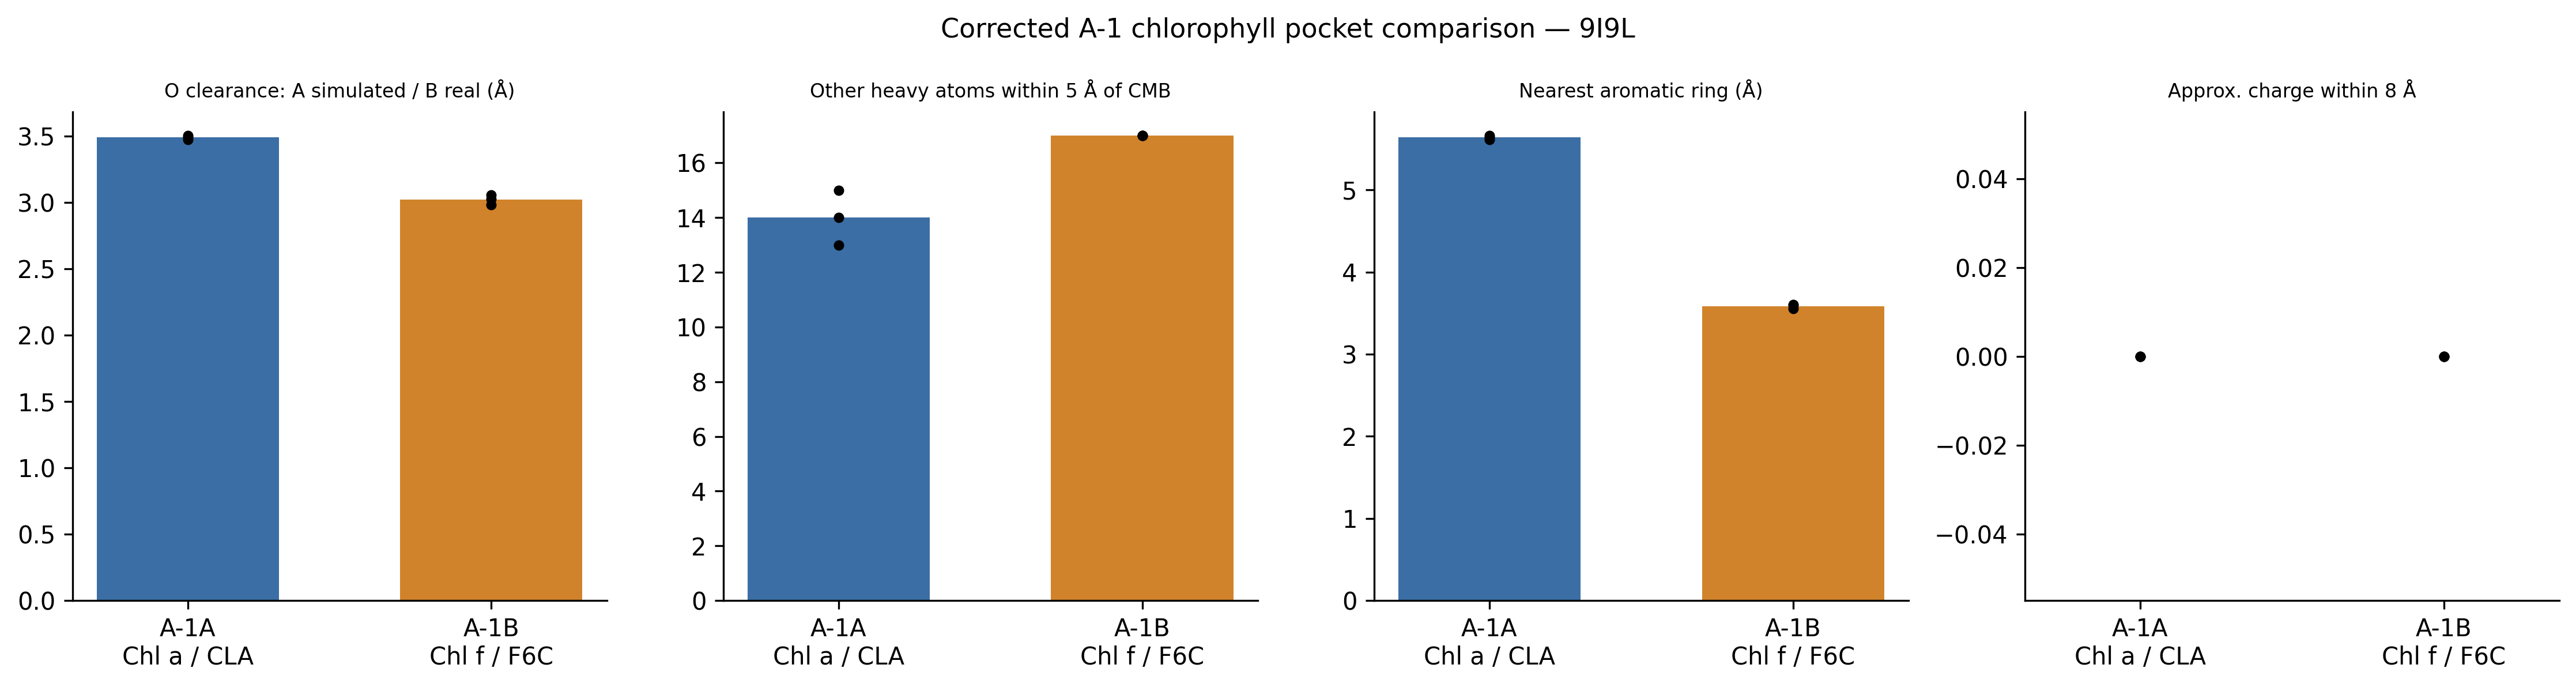


9EYS comparison figure:


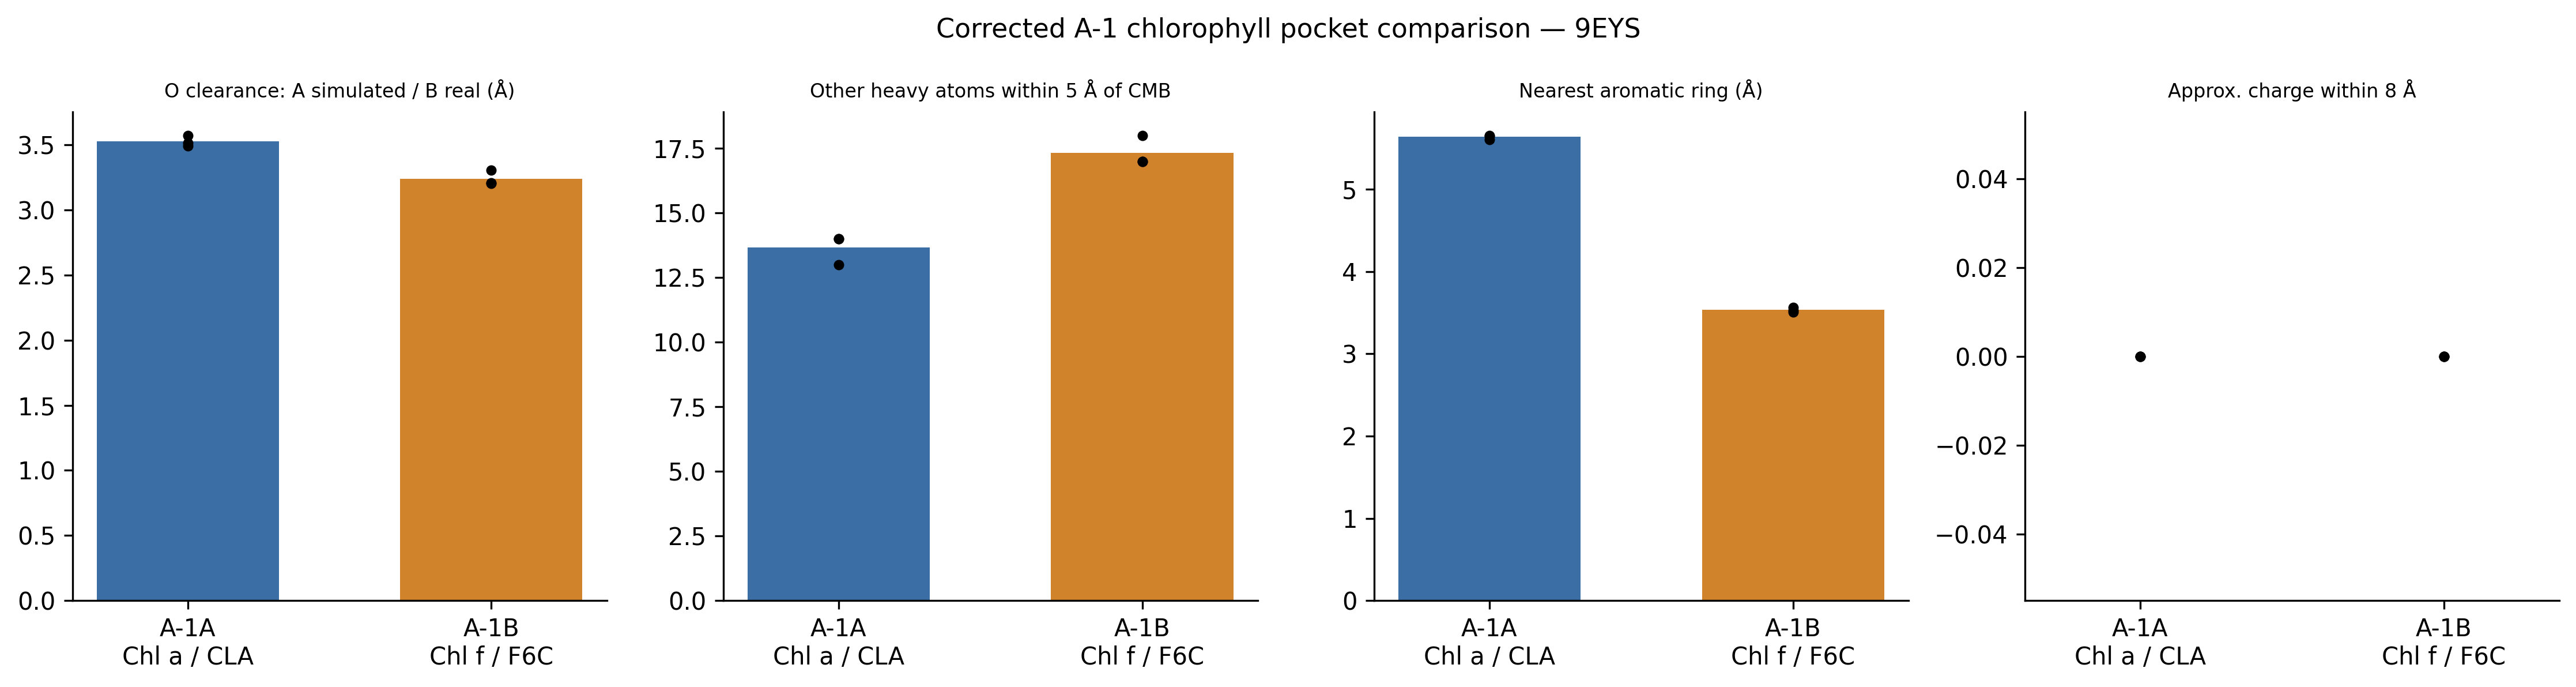

In [20]:
for name, result in [('9I9L', RESULT_9I9L), ('9EYS', RESULT_9EYS)]:
    print(f'\n{name} comparison figure:')
    display(Image(filename=str(result['png']), width=900))


## Step 15 — Optional white-light comparison (1JB0)
Turn `RUN_WHITE_LIGHT_COMPARISON` on only if requested. It compares corresponding *protein residue identities* after sequence alignment; it does not prove a far-red-specific substitution.

In [21]:
RUN_WHITE_LIGHT_COMPARISON = False   # Set to True to run 1JB0 comparisons

if RUN_WHITE_LIGHT_COMPARISON:
    WL_FILE = ensure_structure('1jb0.cif', FOLDERS['Structures'])
    print('White-light reference:', WL_FILE)
    RESULT_9I9L_WL = run_structure('9i9l.cif', wl_name='1jb0.cif')
    RESULT_9EYS_WL = run_structure('9eys.cif', wl_name='1jb0.cif')
else:
    print('White-light comparison skipped. Change the flag to True if needed.')


White-light comparison skipped. Change the flag to True if needed.


## Step 16 — Clean up the **old** version safely (automatic backup)

**This cell runs after both corrected structures are analyzed.** It verifies that the V2 output files exist and that both log files say **Success**. Only then does it remove the **original-version** filenames from the active working folders.

- Previous reports, figures, tables, and logs go to `Rabia..Australia/Old_Version_Backup/` in matching subfolders.
- Your new `_corrected_v2` outputs and `9i9l.cif` / `9eys.cif` structures are **never selected for cleanup**.
- The old `.ipynb` notebook is archived **only if a corrected `.ipynb` is already in `Scripts/`**. Otherwise it remains in place for safety. Once you save the corrected notebook in `Scripts/`, rerun only this cleanup cell.
- You can undo the cleanup later simply by moving the archived files back.

`ARCHIVE_OLD_VERSION = True` enables the cleanup. Set it to `False` if you only want to generate results and keep the old files in place.

In [22]:
# ================== SAFE OLD-VERSION CLEANUP ==================
# This archives (MOVES) the old files; it does NOT delete them permanently.
ARCHIVE_OLD_VERSION = True

# Exact names of files from the *original* analysis.
# Never use a broad glob like *.csv or *.png here: that could move V2 results.
OLD_FILES = {
    'Figures': [
        'a1_pocket_comparison_9i9l.png',
        'a1_pocket_comparison_9i9l.pdf',
        'a1_pocket_comparison_9eys.png',
        'a1_pocket_comparison_9eys.pdf',
    ],
    'Reports': [
        'a1_pocket_comparison_9i9l.txt',
        'a1_pocket_comparison_9eys.txt',
    ],
    'Tables': [
        'a1_pocket_comparison_9i9l.csv',
        'a1_pocket_comparison_9eys.csv',
        'a1_pocket_comparison_9i9l_9eys_combined.csv',
    ],
    'Logs': [
        'a1_pocket_comparison_9i9l.log',
        'a1_pocket_comparison_9eys.log',
    ],
}
OLD_NOTEBOOK_NAME = 'A_1_Chlorophyll_Pocket_Comparison_.ipynb'
BACKUP_ROOT = PROJECT_ROOT / 'Old_Version_Backup'


def cleanup_original_files():
    """Only move known original files after corrected V2 results are present and successful."""
    if not ARCHIVE_OLD_VERSION:
        print('Cleanup disabled: no files moved.')
        return []

    # Safety: never archive unless both corrected analyses and the combined table exist.
    for tag in ('9i9l', '9eys'):
        stem = f'a1_pocket_comparison{CORRECTION_SUFFIX}_{tag}'
        required = {
            'Figures': (stem + '.png', stem + '.pdf'),
            'Reports': (stem + '.txt',),
            'Tables': (stem + '.csv',),
            'Logs': (stem + '.log',),
        }
        for folder_name, names in required.items():
            for name in names:
                path = FOLDERS[folder_name] / name
                if not path.is_file() or path.stat().st_size == 0:
                    raise RuntimeError('Cleanup stopped: missing/empty corrected output: ' + str(path))
        log_path = FOLDERS['Logs'] / (stem + '.log')
        if 'Success UTC:' not in log_path.read_text(encoding='utf-8'):
            raise RuntimeError('Cleanup stopped: V2 execution is not successful: ' + str(log_path))
        report_path = FOLDERS['Reports'] / (stem + '.txt')
        if 'VALIDATED:' not in report_path.read_text(encoding='utf-8'):
            raise RuntimeError('Cleanup stopped: V2 pigment validation output is missing.')

    if not combined_path.is_file() or combined_path.stat().st_size == 0:
        raise RuntimeError('Cleanup stopped: the corrected combined CSV is missing or empty.')
    if '_corrected_v2' not in combined_path.name:
        raise RuntimeError('Cleanup stopped: combined CSV was not a V2 result.')

    # Make sure the Drive path is the intended project folder.
    if PROJECT_ROOT.name != 'Rabia..Australia' or not PROJECT_ROOT.is_dir():
        raise RuntimeError('Cleanup stopped: unexpected project root ' + str(PROJECT_ROOT))

    # Move the original notebook only if a corrected notebook exists in Scripts.
    scripts = FOLDERS['Scripts']
    corrected_notebooks = [
        p for p in scripts.glob('*.ipynb')
        if p.name != OLD_NOTEBOOK_NAME
        and ('corrected' in p.name.lower() or 'v2' in p.name.lower())
        and p.is_file() and p.stat().st_size > 0
    ]
    filenames = {key: list(names) for key, names in OLD_FILES.items()}
    if corrected_notebooks:
        filenames['Scripts'] = [OLD_NOTEBOOK_NAME]
    else:
        print('NOTE: Old notebook stays in Scripts for now.')
        print('To archive it too, first put this corrected .ipynb file in Scripts, then rerun Step 16.')

    moved = []
    for folder_name, names in filenames.items():
        for name in names:
            original = FOLDERS[folder_name] / name
            if not original.exists():
                print('Already absent (or previously archived):', folder_name + '/' + name)
                continue
            if not original.is_file():
                print('Skipped non-file:', original)
                continue
            archive_dir = BACKUP_ROOT / folder_name
            archive_dir.mkdir(parents=True, exist_ok=True)
            archive_target = archive_dir / original.name
            if archive_target.exists():
                # Never overwrite an earlier backup.
                timestamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
                n = 1
                while True:
                    archive_target = archive_dir / f'{original.stem}_backup_{timestamp}_{n}{original.suffix}'
                    if not archive_target.exists():
                        break
                    n += 1
            shutil.move(str(original), str(archive_target))
            moved.append((original, archive_target))
            print('ARCHIVED:', folder_name + '/' + name, '→', archive_target.relative_to(PROJECT_ROOT))

    print('\nCleanup complete:', len(moved), 'old file(s) moved to:', BACKUP_ROOT)
    print('No permanent deletions. CIF structures and corrected_v2 results were not moved.')
    return moved


MOVED_OLD_FILES = cleanup_original_files()


NOTE: Old notebook stays in Scripts for now.
To archive it too, first put this corrected .ipynb file in Scripts, then rerun Step 16.
ARCHIVED: Figures/a1_pocket_comparison_9i9l.png → Old_Version_Backup/Figures/a1_pocket_comparison_9i9l.png
ARCHIVED: Figures/a1_pocket_comparison_9i9l.pdf → Old_Version_Backup/Figures/a1_pocket_comparison_9i9l.pdf
ARCHIVED: Figures/a1_pocket_comparison_9eys.png → Old_Version_Backup/Figures/a1_pocket_comparison_9eys.png
ARCHIVED: Figures/a1_pocket_comparison_9eys.pdf → Old_Version_Backup/Figures/a1_pocket_comparison_9eys.pdf
ARCHIVED: Reports/a1_pocket_comparison_9i9l.txt → Old_Version_Backup/Reports/a1_pocket_comparison_9i9l.txt
ARCHIVED: Reports/a1_pocket_comparison_9eys.txt → Old_Version_Backup/Reports/a1_pocket_comparison_9eys.txt
ARCHIVED: Tables/a1_pocket_comparison_9i9l.csv → Old_Version_Backup/Tables/a1_pocket_comparison_9i9l.csv
ARCHIVED: Tables/a1_pocket_comparison_9eys.csv → Old_Version_Backup/Tables/a1_pocket_comparison_9eys.csv
ARCHIVED: Table

## Step 17 — List the saved results in Google Drive
Confirm the results are present before closing the notebook. You can find them in `My Drive → Rabia..Australia`. To save this notebook itself in the same project, store the `.ipynb` file in the `Scripts` subfolder using Colab's File menu or Google Drive.

In [23]:
print('GOOGLE DRIVE PROJECT:', PROJECT_ROOT)
for folder_name in ['Structures', 'Figures', 'Reports', 'Tables', 'Logs', 'Scripts']:
    print(f'\n[{folder_name}]')
    saved_files = sorted(p for p in FOLDERS[folder_name].iterdir() if p.is_file())
    if not saved_files:
        print('  (empty)')
    for path in saved_files:
        print(f'  {path.name}  ({path.stat().st_size/1024:.1f} KB)')


GOOGLE DRIVE PROJECT: /content/drive/MyDrive/Rabia..Australia

[Structures]
  9eys.cif  (9236.5 KB)
  9i9l.cif  (9147.1 KB)

[Figures]
  a1_pocket_comparison_corrected_v2_9eys.pdf  (22.1 KB)
  a1_pocket_comparison_corrected_v2_9eys.png  (140.1 KB)
  a1_pocket_comparison_corrected_v2_9i9l.pdf  (21.2 KB)
  a1_pocket_comparison_corrected_v2_9i9l.png  (135.3 KB)

[Reports]
  a1_pocket_comparison_corrected_v2_9eys.txt  (6.5 KB)
  a1_pocket_comparison_corrected_v2_9i9l.txt  (6.5 KB)

[Tables]
  a1_pocket_comparison_corrected_v2_9eys.csv  (2.0 KB)
  a1_pocket_comparison_corrected_v2_9i9l.csv  (2.0 KB)
  a1_pocket_comparison_corrected_v2_9i9l_9eys_combined.csv  (3.3 KB)

[Logs]
  a1_pocket_comparison_corrected_v2_9eys.log  (0.2 KB)
  a1_pocket_comparison_corrected_v2_9i9l.log  (0.2 KB)

[Scripts]
  A_1_Chlorophyll_Pocket_Comparison_.ipynb  (427.1 KB)


---
## How to review before sending Rabia

1. Verify all printed **A-1A / CLA** and **A-1B / F6C** candidate pairs with the original paper and biological chain mapping.
2. Confirm the `VALIDATED` lines and successful run logs for both 9I9L and 9EYS.
3. Read the corrected **CMB–OMB real oxygen** measurements at A-1B separately from the **planar hypothetical probes** at A-1A.
4. A nearby O or N is only a *potential* H-bond partner unless hydrogen-bond angles and donor/acceptor identities have been checked.
5. Treat structural differences as correlations, not proof of why the pigments occupy these sites. Do not send raw results as a validated biological explanation until the structural assignment is checked.

**PDB ligand references:** [F6C (Chlorophyll F)](https://www.rcsb.org/ligand/F6C), [CLA (Chlorophyll A)](https://www.rcsb.org/ligand/CLA).

**The old-version outputs are preserved inside `Old_Version_Backup/` after Step 16.** The original notebook is moved only once the corrected `.ipynb` has been saved in `Scripts/`. Corrected output filenames contain `_corrected_v2`.